# Modelo Recomendaro de Peliculas

## Movie Lens

In [1]:
# Importando librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split, StratifiedKFold

In [2]:
calificaciones = pd.read_csv("ml-latest-small/ratings.csv")
peliculas = pd.read_csv("ml-latest-small/movies.csv")
titulo = peliculas.set_index("movieId")["title"]   # para traducir movieId → título

In [3]:
# Imprimiendo el dataframe de peliculas
peliculas.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [4]:
# Imprimiendo el dataframe de calificaciones
calificaciones.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [5]:
# Haciendo validaciones de los datos
n_usuarios = calificaciones["userId"].nunique()
n_peliculas = calificaciones["movieId"].nunique()
print("Calificaciones:", len(calificaciones))
print("Usuarios:", n_usuarios)
print("Películas con al menos una calificación:", n_peliculas)
print(f"Celdas llenas de la tabla usuario × película: {len(calificaciones) / (n_usuarios * n_peliculas):.1%}")

Calificaciones: 100836
Usuarios: 610
Películas con al menos una calificación: 9724
Celdas llenas de la tabla usuario × película: 1.7%


# Exploracion de los datos

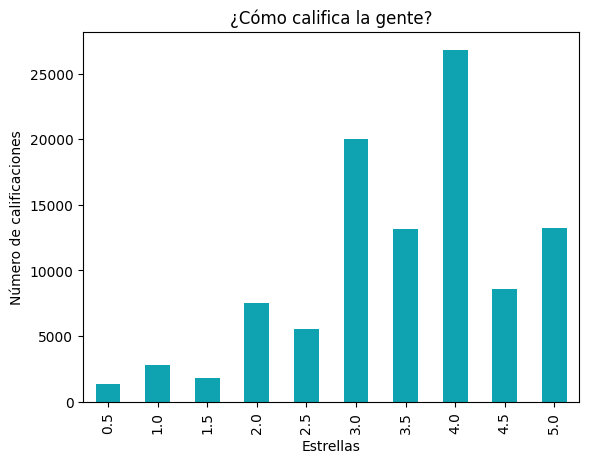

In [6]:
calificaciones["rating"].value_counts().sort_index().plot(kind="bar", color="#0FA3B1")
plt.title("¿Cómo califica la gente?")
plt.xlabel("Estrellas")
plt.ylabel("Número de calificaciones")
plt.show()

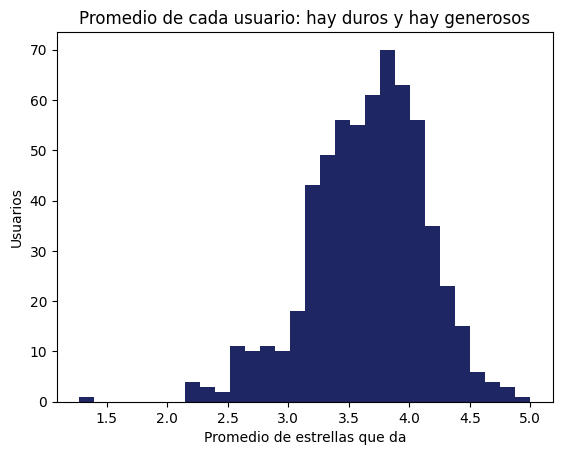

userId
442    1.275000
139    2.144330
508    2.145833
153    2.217877
567    2.245455
         ...   
30     4.735294
25     4.807692
515    4.846154
251    4.869565
53     5.000000
Name: rating, Length: 610, dtype: float64

In [7]:
# Distribucion de promedios de calificacion por usuario
promedio_por_usuario = calificaciones.groupby("userId")["rating"].mean()
promedio_por_usuario.plot(kind="hist", bins=30, color="#1E2664")
plt.title("Promedio de cada usuario: hay duros y hay generosos")
plt.xlabel("Promedio de estrellas que da")
plt.ylabel("Usuarios")
plt.show()
promedio_por_usuario.sort_values()

In [8]:
conteo = calificaciones["movieId"].value_counts()   # calificaciones por película
print("Películas con UNA sola calificación:", (conteo == 1).sum())
print("Mediana de calificaciones por película:", conteo.median())
print("Promedio de calificaciones por película:", conteo.mean())

Películas con UNA sola calificación: 3446
Mediana de calificaciones por película: 3.0
Promedio de calificaciones por película: 10.369806663924312


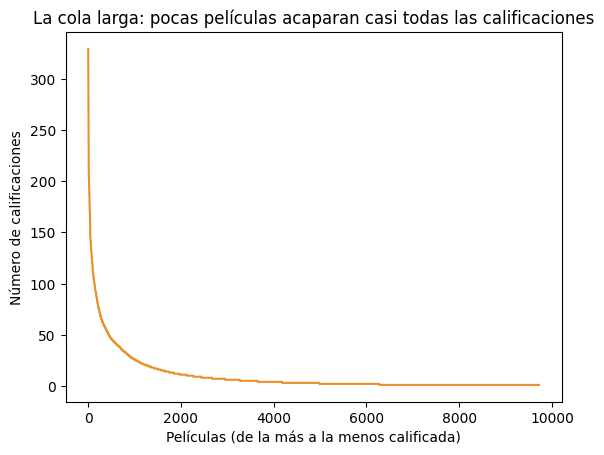

El 10 % más visto de las películas se lleva el 60% de las calificaciones


In [9]:
# ⌨️
plt.plot(conteo.values, color="#E8912B")
plt.title("La cola larga: pocas películas acaparan casi todas las calificaciones")
plt.xlabel("Películas (de la más a la menos calificada)")
plt.ylabel("Número de calificaciones")
plt.show()
top10 = int(len(conteo) * 0.10)
print(f"El 10 % más visto de las películas se lleva el {conteo.head(top10).sum() / conteo.sum():.0%} de las calificaciones")

# Incluyendo mi resena

In [10]:
lista = [1, 3114, 78499, 4886, 6377, 8961, 50872, 68954, 60069, 4306, 364, 588, 5618, 134853, 152081, 106696,
         2571, 260, 1196, 4993, 5952, 7153, 4896, 6539, 480, 1270, 79132, 109487, 72998, 58559, 59315, 89745, 112852, 122904,
         356, 318, 1721, 8533, 3578, 296, 2959, 593, 858, 47, 48516,
         69122, 54503, 7451, 1258, 1997, 1407, 8957, 5679]
pd.set_option("display.max_rows", 60)
peliculas.set_index("movieId").loc[lista, ["title", "genres"]]

,title,genres
movieId,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy
78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX
4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy
6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy
8961,"Incredibles, The (2004)",Action|Adventure|Animation|Children|Comedy
50872,Ratatouille (2007),Animation|Children|Drama
68954,Up (2009),Adventure|Animation|Children|Drama
60069,WALL·E (2008),Adventure|Animation|Children|Romance|Sci-Fi


In [11]:
mis_calificaciones = {
    1: 3.5,        # Toy Story
    6377: 5,     # Finding Nemo
    68954: 5,  # Up
    60069: 5,  # WALL·E
    4306: 5,     # Shrek
    364: 4.5,    # The Lion King
    356: 4,     # Forrest Gump
    260: 3.5,    # Star Wars IV
    50872: 5,     # Ratatouille
    4896: 4,     # Harry Potter I
    152081: 5,  # Zootopia
    134853: 4.5,    # Inside Out
    7451: 5,     # Mean Girls
    112852: 4.5,    # Guardians of the Galaxy
    1258: 3,     # The Shining
    588: 4,    # Aladdin
    1721: 4,     # Titanic
}
mi_perfil = pd.DataFrame({"userId": 0,
                          "movieId": list(mis_calificaciones.keys()),
                          "rating": list(mis_calificaciones.values())})
print("Calificaste", len(mi_perfil), "películas. Tu promedio:", round(mi_perfil["rating"].mean(), 2))

Calificaste 17 películas. Tu promedio: 4.38


In [12]:
# Eliminando la columna de timestamp
del calificaciones["timestamp"]

In [14]:
todas = pd.concat([calificaciones, mi_perfil], ignore_index=True)

# Recomendacion usuario pelicula

In [15]:
populares = conteo[conteo >= 20].index
datos = todas[todas["movieId"].isin(populares)]
print("Películas que conservamos:", len(populares))
print(f"Calificaciones que conservamos: {len(datos) / len(todas):.0%}")

Películas que conservamos: 1297
Calificaciones que conservamos: 67%


In [16]:
# Identificando si tenemos usuarios con las mismas calificaciones en todas las peliculas
resumen = datos.groupby("userId")["rating"].agg(["count", "std"])
resumen[resumen["std"] == 0]

,count,std
userId,,
53,14,0.0


In [17]:
usuarios_validos = resumen[(resumen["count"] >= 10) & (resumen["std"] > 0)].index
datos = datos[datos["userId"].isin(usuarios_validos)]
print("Usuarios que conservamos:", datos["userId"].nunique())
print("¿Sigues tú en los datos?", 0 in usuarios_validos)

Usuarios que conservamos: 608
¿Sigues tú en los datos? True


In [18]:
tabla = datos.pivot_table(index="userId", columns="movieId", values="rating")
print("Forma de la tabla:", tabla.shape)
print(f"Celdas vacías: {tabla.isna().mean().mean():.1%}")
tabla.iloc[:8, :8]

Forma de la tabla: (608, 1297)
Celdas vacías: 91.4%


movieId,1,2,3,5,6,7,10,11
userId,,,,,,,,
0,3.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4.0,NaN,4.0,NaN,4.0,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,4.0,5.0,5.0,4.0,4.0,3.0,4.0
7,4.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


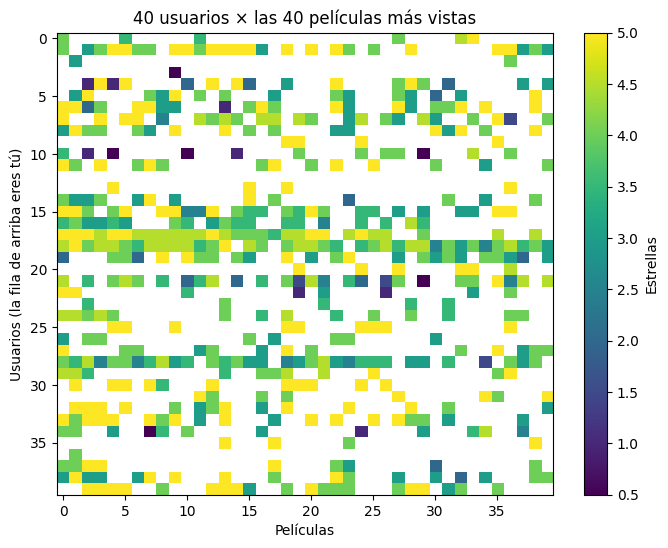

In [19]:
mas_vistas = tabla.count().sort_values(ascending=False).index[:40]
muestra = tabla.loc[tabla.index[:40], mas_vistas]
plt.figure(figsize=(8, 6))
plt.imshow(muestra, cmap="viridis", aspect="auto")
plt.colorbar(label="Estrellas")
plt.title("40 usuarios × las 40 películas más vistas")
plt.xlabel("Películas")
plt.ylabel("Usuarios (la fila de arriba eres tú)")
plt.show()

# Centrando las calificaciones en el promedio del usuario

In [21]:
promedio = tabla.mean(axis=1)                 # promedio de cada usuario
centrada = tabla.sub(promedio, axis=0)        # calificación − su promedio
centrada = centrada.fillna(0)                 # hueco = sin opinión
centrada.loc[0, list(mis_calificaciones)].round(2)   # tus gustos, ya centrados

movieId
1        -0.88
6377      0.62
68954     0.62
60069     0.62
4306      0.62
364       0.12
356      -0.38
260      -0.88
50872     0.62
4896     -0.38
152081    0.62
134853    0.12
7451      0.62
112852    0.12
1258     -1.38
588      -0.38
1721     -0.38
Name: 0, dtype: float64

# Filtrado colaborativo con enfoque usuario a usuario

In [22]:
knn_usuarios = NearestNeighbors(metric="cosine")
knn_usuarios.fit(centrada)

,n_neighbors,5
,radius,1.0
,algorithm,'auto'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,None


In [24]:
distancias, posiciones = knn_usuarios.kneighbors(centrada.loc[[0]], n_neighbors=11)
vecinos = pd.DataFrame({"usuario": centrada.index[posiciones[0]],
                        "similitud": (1 - distancias[0]).round(3)})
vecinos

,usuario,similitud
0,0,1.000
1,306,0.202
2,539,0.198
3,303,0.157
4,544,0.154
5,601,0.152
6,401,0.137
7,308,0.110
8,549,0.107
9,466,0.103


In [25]:
vecino_uno = vecinos["usuario"].iloc[1]
comparacion = tabla.loc[[0, vecino_uno]].T.dropna()
comparacion.index = titulo[comparacion.index]
comparacion

userId,0,306
title,,
Shrek (2001),5.0,3.0
Finding Nemo (2003),5.0,4.0
Ratatouille (2007),5.0,3.5
WALL·E (2008),5.0,5.0
Up (2009),5.0,4.0
Guardians of the Galaxy (2014),4.5,3.0
Inside Out (2015),4.5,4.0
Zootopia (2016),5.0,4.0


## Pasando de vecinos a recomendaciones

In [32]:
def recomendar_usuario_usuario(usuario, k=30, min_vecinos=5, n=20):
    # 1) Los k vecinos más parecidos (el primero es el propio usuario: lo quitamos)
    distancias, posiciones = knn_usuarios.kneighbors(centrada.loc[[usuario]], n_neighbors=k + 1)
    vecinos = centrada.index[posiciones[0][1:]]
    similitud = pd.Series(1 - distancias[0][1:], index=vecinos)

    # 2) Opinión de los vecinos sobre cada película, ponderada por su similitud
    opinion = centrada.loc[vecinos].mul(similitud, axis=0).sum()
    vieron = tabla.loc[vecinos].notna()
    peso = vieron.mul(similitud.abs(), axis=0).sum()
    cuantos = vieron.sum()

    # 3) Predicción = tu promedio + opinión de tus vecinos (sin pasarse de 0.5 a 5 estrellas)
    prediccion = (promedio[usuario] + opinion / peso).clip(0.5, 5)

    # 4) Solo películas que NO has visto y que vieron al menos min_vecinos de tus vecinos
    candidatas = tabla.loc[usuario].isna() & (cuantos >= min_vecinos)
    resultado = pd.DataFrame({"pelicula": titulo[prediccion[candidatas].index].values,
                              "estrellas_predichas": prediccion[candidatas].round(2).values,
                              "vecinos_que_la_vieron": cuantos[candidatas].values})
    return resultado.sort_values("estrellas_predichas", ascending=False).head(n).reset_index(drop=True)
 

In [33]:
recomendar_usuario_usuario(0)

,pelicula,estrellas_predichas,vecinos_que_la_vieron
0,Taxi Driver (1976),5.00,6
1,"Clockwork Orange, A (1971)",5.00,5
2,Dr. Strangelove or: How I Learned to Stop Worr...,5.00,6
3,Spirited Away (Sen to Chihiro no kamikakushi) ...,5.00,8
4,L.A. Confidential (1997),5.00,5
5,"Princess Bride, The (1987)",4.96,10
6,High Fidelity (2000),4.95,5
7,"Monsters, Inc. (2001)",4.90,10
8,This Is Spinal Tap (1984),4.87,6
9,"Avengers, The (2012)",4.87,5


# Filtrado colaborativo con enfoque item a item

In [34]:
por_pelicula = centrada.T                    # filas = películas, columnas = usuarios
knn_peliculas = NearestNeighbors(metric="cosine")
knn_peliculas.fit(por_pelicula)
por_pelicula.shape

(1297, 608)

In [35]:
def parecidas(movie_id, n=10):
    distancias, posiciones = knn_peliculas.kneighbors(por_pelicula.loc[[movie_id]], n_neighbors=n + 1)
    ids = por_pelicula.index[posiciones[0][1:]]          # quitamos a la propia película
    return pd.DataFrame({"pelicula": titulo[ids].values,
                         "similitud": (1 - distancias[0][1:]).round(2)})

print("Parecidas a:", titulo[1])
parecidas(1)

Parecidas a: Toy Story (1995)


,pelicula,similitud
0,Toy Story 2 (1999),0.35
1,Aladdin (1992),0.28
2,Toy Story 3 (2010),0.28
3,Wallace & Gromit: The Wrong Trousers (1993),0.26
4,"Incredibles, The (2004)",0.22
5,Finding Nemo (2003),0.21
6,Blazing Saddles (1974),0.21
7,Back to the Future (1985),0.21
8,Babe (1995),0.20
9,"Lion King, The (1994)",0.19


In [36]:
print(f'Peliculas parecidas a: {titulo[50872]}')
parecidas(50872)

Peliculas parecidas a: Ratatouille (2007)


,pelicula,similitud
0,How to Train Your Dragon (2010),0.27
1,The Lego Movie (2014),0.27
2,"Monsters, Inc. (2001)",0.25
3,Arrival (2016),0.23
4,Iron Man (2008),0.22
5,Finding Nemo (2003),0.21
6,"Hangover, The (2009)",0.20
7,"Grand Budapest Hotel, The (2014)",0.19
8,"Incredibles, The (2004)",0.19
9,"Perks of Being a Wallflower, The (2012)",0.19


In [37]:
K_MAX = 200
dist_peliculas, pos_peliculas = knn_peliculas.kneighbors(n_neighbors=K_MAX)  # vecinas de TODAS (sin sí mismas)

def recomendar_item_item(usuario, k=30, min_vistas=3, n=10):
    mis_notas = centrada.loc[usuario]          # tus calificaciones centradas
    vistas = tabla.loc[usuario].notna()        # películas que ya viste
    filas = []
    for i, pelicula in enumerate(por_pelicula.index):
        if vistas[pelicula]:
            continue                            # ya la viste: no se recomienda
        vecinas = por_pelicula.index[pos_peliculas[i, :k]]
        similitud = 1 - dist_peliculas[i, :k]
        ok = vistas[vecinas].values             # ¿cuáles de sus vecinas viste tú?
        if ok.sum() < min_vistas:
            continue
        pred = promedio[usuario] + (similitud[ok] @ mis_notas[vecinas].values[ok]) / np.abs(similitud[ok]).sum()
        filas.append((titulo[pelicula], round(min(max(pred, 0.5), 5), 2), int(ok.sum())))
    resultado = pd.DataFrame(filas, columns=["pelicula", "estrellas_predichas", "vecinas_que_viste"])
    return resultado.sort_values("estrellas_predichas", ascending=False).head(n).reset_index(drop=True)

In [38]:
recomendar_item_item(0)

,pelicula,estrellas_predichas,vecinas_que_viste
0,Pirates of the Caribbean: The Curse of the Bla...,4.89,4
1,Iron Man (2008),4.88,4
2,Ice Age (2002),4.88,4
3,X-Men (2000),4.81,3
4,"Dark Knight, The (2008)",4.81,3
5,X2: X-Men United (2003),4.81,3
6,"Avengers, The (2012)",4.80,4
7,Django Unchained (2012),4.80,3
8,"Monsters, Inc. (2001)",4.74,4
9,How to Train Your Dragon (2010),4.71,5


In [39]:
# Las dos listas lado a lado
uu = recomendar_usuario_usuario(0)
ii = recomendar_item_item(0)
pd.DataFrame({"usuario-usuario": uu["pelicula"], "ítem-ítem": ii["pelicula"]})

,usuario-usuario,ítem-ítem
0,Taxi Driver (1976),Pirates of the Caribbean: The Curse of the Bla...
1,"Clockwork Orange, A (1971)",Iron Man (2008)
2,Dr. Strangelove or: How I Learned to Stop Worr...,Ice Age (2002)
3,Spirited Away (Sen to Chihiro no kamikakushi) ...,X-Men (2000)
4,L.A. Confidential (1997),"Dark Knight, The (2008)"
5,"Princess Bride, The (1987)",X2: X-Men United (2003)
6,High Fidelity (2000),"Avengers, The (2012)"
7,"Monsters, Inc. (2001)",Django Unchained (2012)
8,This Is Spinal Tap (1984),"Monsters, Inc. (2001)"
9,"Avengers, The (2012)",How to Train Your Dragon (2010)
